# Explore here

In [1]:
import pandas as pd

url = "https://breathecode.herokuapp.com/asset/internal-link?id=733&path=demographic_health_data.csv"
df = pd.read_csv(url)
df.shape

(3140, 108)

In [2]:
list(df.columns)

['fips',
 'TOT_POP',
 '0-9',
 '0-9 y/o % of total pop',
 '19-Oct',
 '10-19 y/o % of total pop',
 '20-29',
 '20-29 y/o % of total pop',
 '30-39',
 '30-39 y/o % of total pop',
 '40-49',
 '40-49 y/o % of total pop',
 '50-59',
 '50-59 y/o % of total pop',
 '60-69',
 '60-69 y/o % of total pop',
 '70-79',
 '70-79 y/o % of total pop',
 '80+',
 '80+ y/o % of total pop',
 'White-alone pop',
 '% White-alone',
 'Black-alone pop',
 '% Black-alone',
 'Native American/American Indian-alone pop',
 '% NA/AI-alone',
 'Asian-alone pop',
 '% Asian-alone',
 'Hawaiian/Pacific Islander-alone pop',
 '% Hawaiian/PI-alone',
 'Two or more races pop',
 '% Two or more races',
 'POP_ESTIMATE_2018',
 'N_POP_CHG_2018',
 'GQ_ESTIMATES_2018',
 'R_birth_2018',
 'R_death_2018',
 'R_NATURAL_INC_2018',
 'R_INTERNATIONAL_MIG_2018',
 'R_DOMESTIC_MIG_2018',
 'R_NET_MIG_2018',
 'Less than a high school diploma 2014-18',
 'High school diploma only 2014-18',
 "Some college or associate's degree 2014-18",
 "Bachelor's degree or 

In [3]:
df.columns[25:70].tolist()

['% NA/AI-alone',
 'Asian-alone pop',
 '% Asian-alone',
 'Hawaiian/Pacific Islander-alone pop',
 '% Hawaiian/PI-alone',
 'Two or more races pop',
 '% Two or more races',
 'POP_ESTIMATE_2018',
 'N_POP_CHG_2018',
 'GQ_ESTIMATES_2018',
 'R_birth_2018',
 'R_death_2018',
 'R_NATURAL_INC_2018',
 'R_INTERNATIONAL_MIG_2018',
 'R_DOMESTIC_MIG_2018',
 'R_NET_MIG_2018',
 'Less than a high school diploma 2014-18',
 'High school diploma only 2014-18',
 "Some college or associate's degree 2014-18",
 "Bachelor's degree or higher 2014-18",
 'Percent of adults with less than a high school diploma 2014-18',
 'Percent of adults with a high school diploma only 2014-18',
 "Percent of adults completing some college or associate's degree 2014-18",
 "Percent of adults with a bachelor's degree or higher 2014-18",
 'POVALL_2018',
 'PCTPOVALL_2018',
 'PCTPOV017_2018',
 'PCTPOV517_2018',
 'MEDHHINC_2018',
 'CI90LBINC_2018',
 'CI90UBINC_2018',
 'Civilian_labor_force_2018',
 'Employed_2018',
 'Unemployed_2018',
 'U

In [4]:
df.columns[70:].tolist()

['Total Hospitals (2019)',
 'Internal Medicine Primary Care (2019)',
 'Family Medicine/General Practice Primary Care (2019)',
 'Total Specialist Physicians (2019)',
 'ICU Beds_x',
 'Total Population',
 'Population Aged 60+',
 'Percent of Population Aged 60+',
 'COUNTY_NAME',
 'STATE_NAME',
 'STATE_FIPS',
 'CNTY_FIPS',
 'county_pop2018_18 and older',
 'anycondition_prevalence',
 'anycondition_Lower 95% CI',
 'anycondition_Upper 95% CI',
 'anycondition_number',
 'Obesity_prevalence',
 'Obesity_Lower 95% CI',
 'Obesity_Upper 95% CI',
 'Obesity_number',
 'Heart disease_prevalence',
 'Heart disease_Lower 95% CI',
 'Heart disease_Upper 95% CI',
 'Heart disease_number',
 'COPD_prevalence',
 'COPD_Lower 95% CI',
 'COPD_Upper 95% CI',
 'COPD_number',
 'diabetes_prevalence',
 'diabetes_Lower 95% CI',
 'diabetes_Upper 95% CI',
 'diabetes_number',
 'CKD_prevalence',
 'CKD_Lower 95% CI',
 'CKD_Upper 95% CI',
 'CKD_number',
 'Urban_rural_code']

In [5]:
[c for c in df.columns if 'prevalence' in c]

['anycondition_prevalence',
 'Obesity_prevalence',
 'Heart disease_prevalence',
 'COPD_prevalence',
 'diabetes_prevalence',
 'CKD_prevalence']

In [6]:
df['Heart disease_prevalence'].describe()

count    3140.000000
mean        8.607803
std         1.758587
min         3.500000
25%         7.400000
50%         8.600000
75%         9.800000
max        15.100000
Name: Heart disease_prevalence, dtype: float64

In [7]:
df = df.rename(columns={'19-Oct': '10-19'})

In [8]:
nulos = df.isnull().sum()
nulos[nulos > 0]

Series([], dtype: int64)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.select_dtypes(exclude='number').columns.tolist()

['COUNTY_NAME', 'STATE_NAME']

In [11]:
enfermedades = ['anycondition', 'Obesity', 'Heart disease', 'COPD', 'diabetes', 'CKD']
cols_salud = [c for c in df.columns if any(e in c for e in enfermedades)]
len(cols_salud)

24

In [12]:
cols_id = ['fips', 'STATE_FIPS', 'CNTY_FIPS', 'COUNTY_NAME', 'STATE_NAME']

In [13]:
y = df['Heart disease_prevalence']
X = df.drop(columns=cols_salud + cols_id)
X.shape

(3140, 79)

In [14]:
correlaciones = X.corrwith(y).sort_values(ascending=False)
correlaciones.head(10), correlaciones.tail(10)

(R_death_2018                                                      0.683237
 PCTPOV017_2018                                                    0.665902
 PCTPOV517_2018                                                    0.650718
 70-79 y/o % of total pop                                          0.641682
 Percent of adults with a high school diploma only 2014-18         0.602560
 Percent of Population Aged 60+                                    0.595762
 PCTPOVALL_2018                                                    0.546347
 Urban_rural_code                                                  0.518151
 60-69 y/o % of total pop                                          0.516140
 Percent of adults with less than a high school diploma 2014-18    0.474498
 dtype: float64,
 % Asian-alone                                                  -0.450503
 20-29 y/o % of total pop                                       -0.459899
 Med_HH_Income_Percent_of_State_Total_2018                      -0.567248
 

In [15]:
X['MEDHHINC_2018'].equals(X['Median_Household_Income_2018'])

True

In [16]:
X = X.loc[:, ~X.T.duplicated()]
X.shape

(3140, 77)

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.shape, X_test.shape

((2512, 77), (628, 77))

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

r2_train = r2_score(y_train, modelo_lineal.predict(X_train))
r2_test = r2_score(y_test, modelo_lineal.predict(X_test))

r2_train, r2_test

(0.9134261633757819, 0.9083799448344644)

In [19]:
from sklearn.linear_model import Lasso

modelo_lasso = Lasso() 
modelo_lasso.fit(X_train, y_train)

r2_score(y_train, modelo_lasso.predict(X_train)), r2_score(y_test, modelo_lasso.predict(X_test)), (modelo_lasso.coef_ != 0).sum()

/home/vscode/.local/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.121112e+03, tolerance: 7.676e-01
  model = cd_fast.enet_coordinate_descent(


(0.7987244259840849, 0.8001701840206089, np.int64(40))

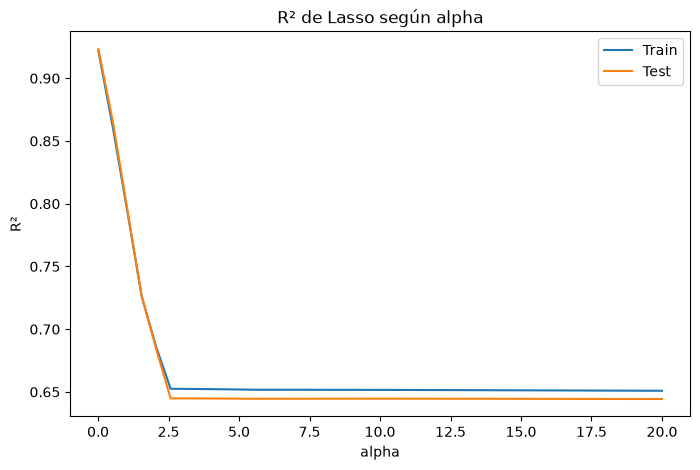

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

alphas = np.linspace(0.01, 20, 40)  # evitamos 0 exacto: con alpha=0 Lasso no converge bien

r2_train_lista = []
r2_test_lista = []

for a in alphas:
    m = Lasso(alpha=a).fit(X_train, y_train)
    r2_train_lista.append(r2_score(y_train, m.predict(X_train)))
    r2_test_lista.append(r2_score(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(alphas, r2_train_lista, label='Train')
plt.plot(alphas, r2_test_lista, label='Test')
plt.xlabel('alpha')
plt.ylabel('R²')
plt.title('R² de Lasso según alpha')
plt.legend()
plt.show()

In [22]:
m10 = Lasso(alpha=10).fit(X_train, y_train)
pd.Series(m10.coef_, index=X_train.columns)[m10.coef_ != 0]

TOT_POP                                      -7.177808e-07
0-9                                           2.233177e-06
20-29                                        -3.475291e-05
30-39                                         1.791567e-05
40-49                                        -4.478206e-06
50-59                                         3.884746e-05
60-69                                         1.617024e-06
70-79                                         6.721792e-05
80+                                          -1.120401e-04
White-alone pop                              -2.554311e-06
Black-alone pop                              -4.194536e-06
Native American/American Indian-alone pop    -6.144141e-06
Asian-alone pop                              -7.344506e-06
Two or more races pop                         2.365189e-05
N_POP_CHG_2018                                3.308185e-05
GQ_ESTIMATES_2018                            -7.664581e-05
Less than a high school diploma 2014-18       2.919870e-

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV

scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)  
X_test_esc = scaler.transform(X_test)        

lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_train_esc, y_train)

lasso_cv.alpha_, r2_score(y_train, lasso_cv.predict(X_train_esc)), r2_score(y_test, lasso_cv.predict(X_test_esc)), (lasso_cv.coef_ != 0).sum()

(np.float64(0.012887907271924218),
 0.9166825144285575,
 0.9198526731525848,
 np.int64(25))

In [24]:
coefs = pd.Series(lasso_cv.coef_, index=X_train.columns)
coefs[coefs != 0].sort_values(key=abs, ascending=False)

Percent of adults with less than a high school diploma 2014-18                   0.386538
MEDHHINC_2018                                                                   -0.360567
70-79 y/o % of total pop                                                         0.358917
PCTPOVALL_2018                                                                   0.323523
20-29 y/o % of total pop                                                        -0.308979
30-39 y/o % of total pop                                                        -0.247919
Med_HH_Income_Percent_of_State_Total_2018                                        0.233919
Percent of adults with a high school diploma only 2014-18                        0.221325
R_death_2018                                                                     0.176448
PCTPOV017_2018                                                                   0.161953
% Black-alone                                                                   -0.136797
80+ y/o % 

## Conclusiones

- **Variable objetivo:** `Heart disease_prevalence` (% de adultos con enfermedad cardíaca por condado, 3,140 condados).
- **Limpieza:** se corrigió la columna `19-Oct` (Excel la convirtió en fecha; era `10-19`), se eliminaron 2 columnas duplicadas, 24 columnas de resultados de salud (para evitar fuga de datos) y 5 identificadores.
- **Modelos (R² test):** regresión lineal 0.908 con 77 variables; Lasso por defecto sin escalar 0.800 (mala comparación por escalas distintas); LassoCV con datos estandarizados 0.920 con 25 variables.
- **Hallazgo principal:** educación, ingreso, pobreza y estructura de edad explican la mayor parte de la prevalencia; los recursos sanitarios (médicos por 100,000 habitantes) tienen un efecto mucho menor.
- **Limitaciones:** datos agregados por condado (falacia ecológica); multicolinealidad entre ingreso, pobreza y educación (los signos individuales no son interpretables como causales); las prevalencias podrían ser estimaciones modeladas a partir de variables demográficas; resultados basados en una sola división train/test.